# Phase 3 Hyperparameter optimization and MLflow

Optimize XGBoost and LightGBM on Development only. Explain near-perfect simulation results, track finite seeded trials, compare baseline and tuned candidates. Production is reserved.

## Completed comparison

| model | variant | pr_auc | roc_auc | fp | fn |
| --- | --- | --- | --- | --- | --- |
| LogisticRegression | baseline | 0.99884966 | 0.99952544 | 2 | 1 |
| RandomForest | baseline | 0.99999735 | 1.00000000 | 3 | 0 |
| XGBoost | baseline | 0.99975950 | 0.99999982 | 0 | 1 |
| LightGBM | baseline | 0.99999340 | 1.00000000 | 0 | 2 |
| XGBoost | tuned | 0.99991859 | 0.99999997 | 0 | 1 |
| LightGBM | tuned | 1.00000000 | 1.00000000 | 0 | 868 |

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
run=json.loads((ROOT/'artifacts/phase3_run.json').read_text())
comparison=pd.read_csv(ROOT/'artifacts/tuned_model_comparison.csv')
trials=pd.read_csv(ROOT/'artifacts/optimization_trials.csv')
search=json.loads((ROOT/'artifacts/hyperparameter_search_space.json').read_text())


## Why Average Precision

Validation has only 868 frauds among 1,398,242 transactions. Accuracy is uninformative. Exact Average Precision is the optimization objective, with ROC-AUC secondary. Threshold 0.5 remains comparative; ranking evaluates scarce review capacity.

## Sanity check before tuning

Every persisted Development feature row was reconstructed from the raw data. No target, flag, post-event balance or raw identifier is a predictor. Mutating prohibited fields preserves features. The fixed approximate-emptying rule explains almost all positives; the implementation audit does not guarantee absence of simulation shortcuts.

In [2]:
display(Markdown((ROOT/'docs/perfect_performance_sanity_check.md').read_text(encoding='utf-8-sig')))
univariate=pd.read_csv(ROOT/'artifacts/sanity_univariate_features.csv')
display(univariate.loc[univariate.segment=='validation'].sort_values('pr_auc_high',ascending=False))
display(pd.read_csv(ROOT/'artifacts/sanity_simple_rules.csv'))

# Perfect performance sanity check



All checks use Development only. Every saved model-matrix row and target was reconstructed from raw rows at steps 1–400; arrays were not rewritten. Train steps 1–320 and Validation steps 321–400 are strictly disjoint.

## Leakage evidence

{
  "verified_rows": {
    "train": 4388788,
    "validation": 1398242
  },
  "exact_reconstruction": true,
  "prohibited_column_mutation_invariant": true,
  "train_steps": [
    1,
    320
  ],
  "validation_steps": [
    321,
    400
  ],
  "shared_rows": false,
  "shared_rows_evidence": "Strictly disjoint step values; exact rows include step; Phase 1 found no exact duplicates",
  "production_used": false,
  "feature_names": [
    "step",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "amount_to_oldbalanceOrg",
    "orig_balance_zero",
    "orig_balance_emptied",
    "dest_is_merchant",
    "type_CASH_IN",
    "type_CASH_OUT",
    "type_DEBIT",
    "type_PAYMENT",
    "type_TRANSFER",
    "type_UNKNOWN"
  ],
  "preprocessing_review": "Row-local features have no fit; logistic StandardScaler fitted by Pipeline on Train only",
  "matrix_sha256": {
    "train_X.npy": "4a74d6444772904aa01e524e178627c1e4c5b6efb8443c5da7870cd0a8da16e9",
    "train_y.npy": "d6500bdffc2eb7fdb7a93fe92ee66224e48305c88adc8a935a917a3351239647",
    "validation_X.npy": "dc1066ec7f9d3cd8cea756c9dc4ae6b7d5dd94b7d7e2a9f8b1344cab3bcfb2dd",
    "validation_y.npy": "32f5950840801da44ba733ced3aa5b7b1b52ff463cc8e21ad6d677479c19cb29"
  },
  "phase2_source_sha256": {
    "src/fraud_detection/features.py": "73badebaa186e2fc323fd6c46de784b5002c380dca7ac360a70f7a9a32c0f28a",
    "src/fraud_detection/modeling.py": "e14378a4b51691ef03bdebc45c7018a83a2ce1832d503c19544c8d4d7e69cfc3",
    "scripts/run_baselines.py": "214fdac476209b002446ba32222f442df65a3f4c0b0c8600f745667583d860e6",
    "PHASE_2_MODELING_REPORT.md": "d95c8e5fdcd5573e9a9754db22bf74e84e81ae33dc5d52a1ef66fe0dc917ab9b"
  },
  "all_fraud_development_steps": 137,
  "all_fraud_step_transactions": 1524,
  "seconds": 61.56280160000097,
  "conclusion": "B: No implementation leakage detected; near-deterministic simulator patterns. C: Operational availability and external validity remain uncertain."
}

The fixed MODEL_COLUMNS list excludes isFraud, isFlaggedFraud, raw IDs, new balances and every post-event derivative. Raw reconstruction confirms columns were not replaced by accidental target-derived data. Mutating labels, flags, post-event balances and IDs (preserving only destination prefix) leaves features identical. Source review confirms no fitted transformer spans Train and Validation. This provides evidence against implementation leakage, not proof that the simulator contains no target-related shortcuts.

## Univariate separation

Both high and low score directions are reported descriptively. AP for binary features is based on only two score groups and is not equivalent to precision among positive-feature rows. Constant features return prevalence AP and ROC 0.5. These checks do not select or remove model predictors.

| segment | feature | pr_auc_high | pr_auc_low | roc_auc_high |
| --- | --- | --- | --- | --- |
| train | step | 0.02113342 | 0.00104179 | 0.46204322 |
| train | amount | 0.01309433 | 0.00130569 | 0.78350650 |
| train | oldbalanceOrg | 0.00214300 | 0.00047405 | 0.80300810 |
| train | oldbalanceDest | 0.00067205 | 0.00119398 | 0.36681187 |
| train | amount_to_oldbalanceOrg | 0.00260020 | 0.00116140 | 0.68857726 |
| train | orig_balance_zero | 0.00081609 | 0.00121758 | 0.33796384 |
| train | orig_balance_emptied | 0.97868185 | 0.00080537 | 0.98947065 |
| train | dest_is_merchant | 0.00082232 | 0.00124161 | 0.33101328 |
| train | type_CASH_IN | 0.00082232 | 0.00105278 | 0.39045647 |
| train | type_CASH_OUT | 0.00099498 | 0.00072848 | 0.57410970 |
| train | type_DEBIT | 0.00082232 | 0.00082744 | 0.49690606 |
| train | type_PAYMENT | 0.00082232 | 0.00124161 | 0.33101328 |
| train | type_TRANSFER | 0.00287368 | 0.00063547 | 0.70751449 |
| train | type_UNKNOWN | 0.00082232 | 0.00082232 | 0.50000000 |
| validation | step | 0.00068204 | 0.00054489 | 0.54252289 |
| validation | amount | 0.00668282 | 0.00151457 | 0.78445063 |
| validation | oldbalanceOrg | 0.00401586 | 0.00035467 | 0.81948373 |
| validation | oldbalanceDest | 0.00051752 | 0.00090464 | 0.36830634 |
| validation | amount_to_oldbalanceOrg | 0.00189616 | 0.00089605 | 0.67853368 |
| validation | orig_balance_zero | 0.00062007 | 0.00093753 | 0.33103338 |
| validation | orig_balance_emptied | 0.98157826 | 0.00060955 | 0.99078341 |
| validation | dest_is_merchant | 0.00062078 | 0.00093203 | 0.33292340 |
| validation | type_CASH_IN | 0.00062078 | 0.00079808 | 0.38885188 |
| validation | type_CASH_OUT | 0.00075134 | 0.00054987 | 0.57406857 |
| validation | type_DEBIT | 0.00062078 | 0.00062524 | 0.49642866 |
| validation | type_PAYMENT | 0.00062078 | 0.00093203 | 0.33292340 |
| validation | type_TRANSFER | 0.00214046 | 0.00047997 | 0.70772749 |
| validation | type_UNKNOWN | 0.00062078 | 0.00062078 | 0.50000000 |

## Simple rules

Rules use fixed tolerances from Phase 2 and no learned thresholds. The ratio check uses a prespecified 1e-6 diagnostic tolerance on stored float32; the emptied feature itself was computed from raw float64 with absolute monetary tolerance 0.01. Rules with incomplete recall or false positives explain most separation without being equivalent to the label.

| segment | rule | pr_auc | precision_05 | recall_05 | tp | fp | tn | fn |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| train | TRANSFER | 0.00287368 | 0.00494674 | 0.49736769 | 1795 | 361070 | 4024109 | 1814 |
| train | CASH_OUT | 0.00099498 | 0.00116583 | 0.50263231 | 1814 | 1554164 | 2831015 | 1795 |
| train | TRANSFER_or_CASH_OUT | 0.00188082 | 0.00188082 | 1.00000000 | 3609 | 1915234 | 2469945 | 0 |
| train | origin_zero | 0.00081609 | 0.00001924 | 0.00775838 | 28 | 1455137 | 2930042 | 3581 |
| train | amount_approximately_prior_balance | 0.97868185 | 0.99971703 | 0.97894154 | 3533 | 1 | 4385178 | 76 |
| train | ratio_approximately_one_positive_balance | 0.97895885 | 1.00000000 | 0.97894154 | 3533 | 0 | 4385179 | 76 |
| train | risky_type_and_requested_emptying | 0.97895885 | 1.00000000 | 0.97894154 | 3533 | 0 | 4385179 | 76 |
| validation | TRANSFER | 0.00214046 | 0.00366013 | 0.50000000 | 434 | 118141 | 1279233 | 434 |
| validation | CASH_OUT | 0.00075134 | 0.00088190 | 0.50000000 | 434 | 491684 | 905690 | 434 |
| validation | TRANSFER_or_CASH_OUT | 0.00142134 | 0.00142134 | 1.00000000 | 868 | 609825 | 787549 | 0 |
| validation | origin_zero | 0.00062007 | 0.00000211 | 0.00115207 | 1 | 473829 | 923545 | 867 |
| validation | amount_approximately_prior_balance | 0.98157826 | 1.00000000 | 0.98156682 | 852 | 0 | 1397374 | 16 |
| validation | ratio_approximately_one_positive_balance | 0.98157826 | 1.00000000 | 0.98156682 | 852 | 0 | 1397374 | 16 |
| validation | risky_type_and_requested_emptying | 0.98157826 | 1.00000000 | 0.98156682 | 852 | 0 | 1397374 | 16 |

## Conclusion

A. No implementation evidence of direct target, business-rule, post-event, identifier or temporal leakage was detected.

B. Near-deterministic simulator patterns are present: requested account emptying and transaction type sharply separate the target. Low-volume steps can contain only fraud, adding a simulation scheduling shortcut. This explains why very high AP is plausible without prohibited predictors.

C. Pending uncertainty: pre-execution balance availability and merchant-prefix semantics in a real system; simulation label-generation mechanisms; single-holdout stability; external transferability and score calibration. A dataset-level generator shortcut cannot be ruled out by an implementation audit. Do not infer extraordinary real-world performance.

The same Validation will subsequently support tuning and early stopping as authorized. Its final scores will then be development-selection estimates, not independent unbiased test evidence. Production remains reserved.


,segment,feature,pr_auc_high,pr_auc_low,roc_auc_high
20,validation,orig_balance_emptied,0.981578,0.000610,0.990783
15,validation,amount,0.006683,0.001515,0.784451
16,validation,oldbalanceOrg,0.004016,0.000355,0.819484
26,validation,type_TRANSFER,0.002140,0.000480,0.707727
18,validation,amount_to_oldbalanceOrg,0.001896,0.000896,0.678534
23,validation,type_CASH_OUT,0.000751,0.000550,0.574069
14,validation,step,0.000682,0.000545,0.542523
24,validation,type_DEBIT,0.000621,0.000625,0.496429
22,validation,type_CASH_IN,0.000621,0.000798,0.388852
21,validation,dest_is_merchant,0.000621,0.000932,0.332923


,segment,rule,pr_auc,roc_auc,precision_05,recall_05,f1_05,f2_05,tp,fp,tn,fn,k_0.1pct,precision_top_0.1pct,recall_top_0.1pct,k_0.5pct,precision_top_0.5pct,recall_top_0.5pct,k_1pct,precision_top_1pct,recall_top_1pct
0,train,TRANSFER,0.002874,0.707514,0.004947,0.497368,0.009796,0.023787,1795,361070,4024109,1814,4389,0.010481,0.012746,21944,0.003737,0.022721,43888,0.002620,0.031865
1,train,CASH_OUT,0.000995,0.574110,0.001166,0.502632,0.002326,0.005776,1814,1554164,2831015,1795,4389,0.009569,0.011638,21944,0.002552,0.015517,43888,0.001413,0.017179
2,train,TRANSFER_or_CASH_OUT,0.001881,0.781624,0.001881,1.000000,0.003755,0.009334,3609,1915234,2469945,0,4389,0.018000,0.021890,21944,0.004648,0.028263,43888,0.002734,0.033250
3,train,origin_zero,0.000816,0.337964,0.000019,0.007758,0.000038,0.000095,28,1455137,2930042,3581,4389,0.000456,0.000554,21944,0.000137,0.000831,43888,0.000114,0.001385
4,train,amount_approximately_prior_balance,0.978682,0.989471,0.999717,0.978942,0.989220,0.983027,3533,1,4385178,76,4389,0.805195,0.979219,21944,0.161183,0.980050,43888,0.080614,0.980327
5,train,ratio_approximately_one_positive_balance,0.978959,0.989471,1.000000,0.978942,0.989359,0.983082,3533,0,4385179,76,4389,0.805195,0.979219,21944,0.161183,0.980050,43888,0.080614,0.980327
6,train,risky_type_and_requested_emptying,0.978959,0.989471,1.000000,0.978942,0.989359,0.983082,3533,0,4385179,76,4389,0.805195,0.979219,21944,0.161183,0.980050,43888,0.080614,0.980327
7,validation,TRANSFER,0.002140,0.707727,0.003660,0.500000,0.007267,0.017780,434,118141,1279233,434,1399,0.002859,0.004608,6992,0.002717,0.021889,13983,0.002432,0.039171
8,validation,CASH_OUT,0.000751,0.574069,0.000882,0.500000,0.001761,0.004379,434,491684,905690,434,1399,0.000000,0.000000,6992,0.000572,0.004608,13983,0.000787,0.012673
9,validation,TRANSFER_or_CASH_OUT,0.001421,0.781796,0.001421,1.000000,0.002839,0.007067,868,609825,787549,0,1399,0.000000,0.000000,6992,0.001144,0.009217,13983,0.001001,0.016129


## Candidate algorithms

XGBoost and LightGBM offer compact boosting models, fast histogram training and controllable regularization. They also support later tree-explanation workflows, which are outside this phase. Logistic regression is the interpretable reference. Random Forest remains a strong baseline without expensive tuning.

## Prespecified search space

| algorithm | parameter | range | scale | rationale |
| --- | --- | --- | --- | --- |
| XGBoost | n_estimators | 80 to 200 | int | Upper bound on boosting rounds; early stopping may use fewer |
| XGBoost | max_depth | 3 to 7 | int | Bound tree complexity |
| XGBoost | learning_rate | 0.03 to 0.15 | log | Moderate shrinkage |
| XGBoost | min_child_weight | 0.5 to 10.0 | log | Leaf Hessian regularization |
| XGBoost | subsample | 0.8 to 1.0 | float | Controlled row sampling inside Train |
| XGBoost | colsample_bytree | 0.8 to 1.0 | float | Controlled feature sampling |
| XGBoost | reg_alpha | 0.0001 to 1.0 | log | L1 regularization |
| XGBoost | reg_lambda | 0.5 to 5.0 | log | L2 regularization |
| XGBoost | gamma | 0.0 to 1.0 | float | Split gain requirement |
| XGBoost | scale_pos_weight | 1, 10, 100 | categorical | Controlled native weights, no full inverse-prevalence assumption |
| LightGBM | n_estimators | 80 to 200 | int | Upper bound on boosting rounds |
| LightGBM | learning_rate | 0.03 to 0.15 | log | Moderate shrinkage |
| LightGBM | num_leaves | 15 to 31 | int | Bound leaf count; capped by selected depth |
| LightGBM | max_depth | 4 to 7 | int | Bound tree complexity |
| LightGBM | min_child_samples | 20 to 100 | int | Minimum leaf observations |
| LightGBM | subsample | 0.8 to 1.0 | float | Train bagging; subsample_freq fixed to 1 |
| LightGBM | colsample_bytree | 0.8 to 1.0 | float | Feature sampling |
| LightGBM | reg_alpha | 0.0001 to 1.0 | log | L1 regularization |
| LightGBM | reg_lambda | 0.5 to 5.0 | log | L2 regularization |
| LightGBM | scale_pos_weight | 1, 10, 100 | categorical | Controlled native weights, no full inverse-prevalence assumption |

## Optuna protocol

Sequential TPESampler seed 42, five startup trials, one enqueued baseline-like configuration, direction maximize, exact Validation AP. Maximum 20 trials; minimum 10 before the fixed saturation criterion (AP >=0.9999, last-five improvement <=0.00001) can stop. No Optuna pruning; estimator early stopping uses Validation only, patience 20. XGBoost aucpr differs from exact AP; LightGBM monitors average_precision. LightGBM retains the numerical leaf-step guard and enables bagging frequency 1.

{'XGBoost': {'study_name': '20261004T152211371659Z_XGBoost', 'trials': 10, 'best_trial': 7, 'best_parameters': {'n_estimators': 148, 'max_depth': 6, 'learning_rate': 0.1469541059356907, 'min_child_weight': 3.532871354926938, 'subsample': 0.9942734367531818, 'colsample_bytree': 0.8825728131957696, 'reg_alpha': 0.02165779390916417, 'reg_lambda': 0.5395608952674368, 'gamma': 0.9674364834653933, 'scale_pos_weight': 10.0}, 'best_trial_value': 0.9999185900788442, 'best_trial_run_id': '1fbb627a70de438b8aefa60154a1f57d', 'stop_reason': 'prespecified_practical_saturation', 'trial_pr_auc_min': 0.998849082523785, 'trial_pr_auc_max': 0.9999185900788442, 'best_run_id': '1d353308f1e3427094a221667f3da9de', 'refit_matches_best_trial': True}, 'LightGBM': {'study_name': '20261004T152211371659Z_LightGBM', 'trials': 10, 'best_trial': 0, 'best_parameters': {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 5, 'num_leaves': 31, 'min_child_samples': 20, 'subsample': 1.0, 'colsample_bytree': 1.0, 'reg_a

,algorithm,trial,pr_auc,fp,fn,effective_iterations,training_seconds,mlflow_run_id
0,XGBoost,0,0.999747,0,1,36,17.860341,c59c39c3a2c94ac09c84ab4910a6971b
1,XGBoost,1,0.999842,0,868,2,10.690083,e2ed011b3ba047e7bded7d278c8b0115
2,XGBoost,2,0.999842,0,2,15,13.052255,ec2c94b13a2f4c8b9d28731222d400a7
3,XGBoost,3,0.999919,0,1,37,20.843402,dfeb3a494f8d46a184212798089f23ec
4,XGBoost,4,0.999021,0,1,46,22.852566,023cd1c3521a4affbf7912a1ce58fe09
5,XGBoost,5,0.998849,0,16,21,15.218742,cdeaeffbe978456a93bbf642eeb10b8d
6,XGBoost,6,0.999842,0,1,51,24.857212,41f73af9dba14a7d97371b548fa1e4b8
7,XGBoost,7,0.999919,0,1,24,17.285936,1fbb627a70de438b8aefa60154a1f57d
8,XGBoost,8,0.998849,0,868,6,9.475048,c11529857b7c4030b5589c588f94008a
9,XGBoost,9,0.999805,0,1,16,15.505879,3ee468511a6c4f6fb78bfa8693c82928


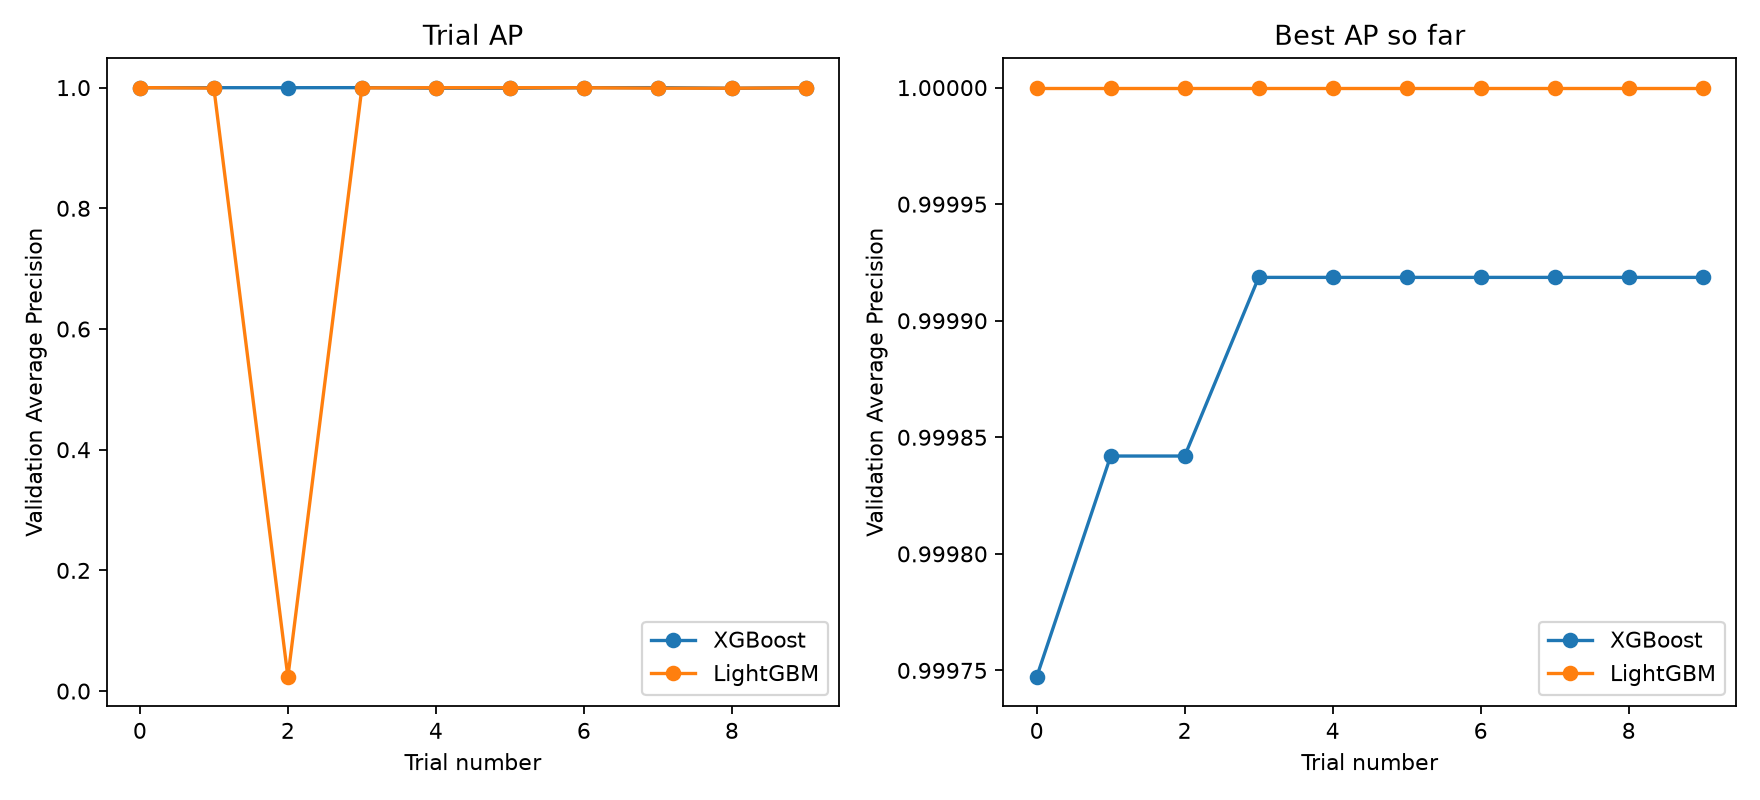

In [3]:
display(run['algorithms'])
display(trials[['algorithm','trial','pr_auc','fp','fn','effective_iterations','training_seconds','mlflow_run_id']])
display(Image(filename=str(ROOT/'reports/figures/phase3_optimization_history.png')))

## MLflow tracking

Local SQLite metadata and local artifacts; parent runs per algorithm, child run per trial, saved best-trial runs, Phase 2 baseline references and comparison summary. No dataset or credentials are logged. DagsHub setup is prepared without a remote experiment link.

In [4]:
display({k:run[k] for k in ['experiment_name','experiment_id','tracking_uri','mlflow_run_count','all_runs_finished']})
display(pd.DataFrame(run['runs']))
display(Markdown((ROOT/'docs/mlflow_dagshub_setup.md').read_text(encoding='utf-8-sig')))

{'experiment_name': 'fraud-detection-hyperparameter-optimization', 'experiment_id': '1', 'tracking_uri': 'sqlite:///./mlruns/mlflow.db', 'mlflow_run_count': 29, 'all_runs_finished': True}

,role,algorithm,run_id,trial
0,baseline_reference,LogisticRegression,7fa24d6ea79f4b6d8f62a07236a351f9,NaN
1,baseline_reference,RandomForest,33845df18b4a48288e116b0027e6b946,NaN
2,baseline_reference,XGBoost,ac0682a9e54a4f75a3b63cd052a1fdc6,NaN
3,baseline_reference,LightGBM,e5b6ee1abaca488095f18010663e5166,NaN
4,algorithm_parent,XGBoost,d18fbdce26b74ebf97073b110eca54c2,NaN
5,trial,XGBoost,c59c39c3a2c94ac09c84ab4910a6971b,0.0
6,trial,XGBoost,e2ed011b3ba047e7bded7d278c8b0115,1.0
7,trial,XGBoost,ec2c94b13a2f4c8b9d28731222d400a7,2.0
8,trial,XGBoost,dfeb3a494f8d46a184212798089f23ec,3.0
9,trial,XGBoost,023cd1c3521a4affbf7912a1ce58fe09,4.0


# MLflow local and DagsHub setup

Phase 3 is runnable locally without a remote repository or credentials. No remote was created, no push was performed and no external experiment link exists yet. DagsHub integration is prepared through MLflow environment variables; it was not connected or exercised remotely.

## Reproduce the phase in PowerShell

Run at the fraud-detection-ml-monitoring repository root:

```powershell
$env:UV_CACHE_DIR = Join-Path $PWD '.uv-cache'
uv sync --locked
uv run python -m pytest -q
uv run python scripts/run_sanity_checks.py
uv run python scripts/run_optimization.py --max-trials 20 --minimum-trials 10
uv run python scripts/build_phase3_report.py
```

The sanity script verifies every persisted Development matrix row against features reconstructed from the raw Development CSV. It does not rewrite Phase 2 matrices or outputs. Optimization requires the persisted matrices and matching sanity hashes. Missing matrices are a prerequisite failure; do not rerun the Phase 1 audit. To reproduce the full project from scratch, follow the Phase 2 preparation command separately before Phase 3.

Optuna uses sequential seeded TPE (seed 42, five startup trials), an initial baseline-like trial, exact Validation Average Precision maximization and estimator early stopping. Trials run on full Train without class resampling; row bagging parameters are algorithm-native regularization, not an artificial class-balanced dataset. A prespecified practical plateau may stop a study after at least ten completed trials when best AP >=0.9999 and best improvement over the last five trials <=0.00001. Otherwise the limit is twenty. This is a compute rule, not evidence of statistically equivalent models. Validation is reused for tuning and early stopping, so tuned scores are development-selection estimates. Production is never used.

Repeated complete executions create distinct named studies and MLflow runs. They do not silently resume an old study. Seeded single-process trials reproduce suggestions on the same locked environment; cross-version/platform timing and numerical differences remain possible. Optuna persistence supports audit, not an implicit resume command. Do not increase the search budget to chase meaningless decimals.

## Local tracking location and UI

Metadata: `mlruns/mlflow.db` (SQLite). MLflow artifacts: `mlartifacts/`. Optuna: `optuna_studies/phase3.db`. All three stores are ignored by Git. Only small result/configuration CSV and JSON files, reports, code and figures may be versioned. The native best models are stored under ignored `data/processed/phase3_models/` and as MLflow artifacts, with the ordered feature list and a model manifest. Datasets, full score arrays and credentials are never logged.

```powershell
$trackingUri = 'sqlite:///' + (Join-Path $PWD 'mlruns/mlflow.db').Replace('\', '/')
uv run mlflow ui --backend-store-uri $trackingUri --host 127.0.0.1 --port 5000
```

Open http://127.0.0.1:5000 in your browser and select `fraud-detection-hyperparameter-optimization`. The UI is local to this computer; it is not a public experiment link. Parent runs group each algorithm, nested child runs represent trials, best-trial runs reproduce and save the selected models, baseline reference runs import Phase 2 evidence without retraining, and a summary run contains comparison and champion rationale. `artifacts/phase3_run.json` lists the execution id, study names, run ids, count and experiment id. Reports can be regenerated without training using `build_phase3_report.py`.

## Connect DagsHub later

Prerequisites: an actual user-approved DagsHub repository, its verified MLflow tracking URL and your own access authorization. Obtain the real tracking endpoint from that repository's integration panel. The project does not create any of these prerequisites.

Set values only in the current PowerShell process; do not put them into code, notebooks, `.env` files, Git, parameters or artifacts:

```powershell
$env:MLFLOW_TRACKING_URI = Read-Host 'URL real de MLflow en tu repositorio DagsHub'
$env:MLFLOW_TRACKING_USERNAME = Read-Host 'Usuario DagsHub'
$dagshubToken = Read-Host 'Token personal DagsHub' -AsSecureString
$env:MLFLOW_TRACKING_PASSWORD = [System.Net.NetworkCredential]::new('', $dagshubToken).Password
# Execute only when remote tracking has been explicitly authorized:
uv run python scripts/run_optimization.py --allow-remote-tracking
Remove-Item Env:MLFLOW_TRACKING_PASSWORD
Remove-Item Env:MLFLOW_TRACKING_USERNAME
Remove-Item Env:MLFLOW_TRACKING_URI
```

Remote tracking requires the explicit CLI flag even if an inherited environment variable points at a remote server. Credential-containing URLs are rejected. The remote MLflow backend chooses its artifact location; credentials are never included in logged parameters or environment metadata. Do not print the environment variables. When access exists and remote logging has succeeded, capture the real experiment link from that UI for the academic submission. Local execution remains independently supported.

## Model loading

XGBoost: instantiate XGBClassifier and load the best `.ubj` model. Its saved best-iteration metadata preserves early-stopping prediction behavior. LightGBM: instantiate Booster(model_file=...) using the best native `.txt` file saved at best_iteration. Construct features with the Phase 2 engineer_features function and exact MODEL_COLUMNS ordering before inference. No production threshold is selected; 0.5 remains a comparative convention. These native files are local candidate models, not a deployed service or final production champion.

## Primary implementation references

- [MLflow local SQLite tracking](https://www.mlflow.org/docs/latest/ml/tracking/tutorials/local-database/)
- [MLflow Python tracking API](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.html)
- [Optuna seeded TPE sampler](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html)
- [XGBoost sklearn and early-stopping API](https://xgboost.readthedocs.io/en/stable/python/python_api.html)
- [LightGBM metrics and parameters](https://lightgbm.readthedocs.io/en/stable/Parameters.html)
- [DagsHub MLflow integration](https://dagshub.com/docs/integration_guide/mlflow_tracking/)

MLflow includes web-serving libraries transitively; no project web application, dashboard, deployment or monitoring code is implemented in Phase 3.


## Baseline versus tuned results

Scores are development-selection estimates because Validation is reused for tuning and early stopping. Near-equal AP does not establish statistically significant superiority; compare operational errors, latency, effective iterations and trial stability.

,model,train_observations,validation_observations,training_seconds,prediction_seconds,pr_auc,roc_auc,precision_05,recall_05,f1_05,f2_05,tp,fp,tn,fn,k_0.1pct,precision_top_0.1pct,recall_top_0.1pct,k_0.5pct,precision_top_0.5pct,recall_top_0.5pct,k_1pct,precision_top_1pct,recall_top_1pct,variant,best_parameters,effective_iterations
0,LogisticRegression,4388788,1398242,10.116063,0.189498,0.998850,0.999525,0.997699,0.998848,0.998273,0.998618,867,2,1397372,1,1399,0.619728,0.998848,6992,0.123999,0.998848,13983,0.062004,0.998848,baseline,"{""logisticregression"": ""LogisticRegression(class_weight='balanced', max_iter=400, random_state=42)"", ""logisticregression__C"": ""1.0"", ""logisticregression__class_weight"": ""balanced"", ""logisticregression__dual"": ""False"", ""logisticregression__fit_intercept"": ""True"", ""logisticregression__intercept_scaling"": ""1"", ""logisticregression__l1_ratio"": ""0.0"", ""logisticregression__max_iter"": ""400"", ""logisticregression__n_jobs"": ""None"", ""logisticregression__penalty"": ""deprecated"", ""logisticregression__random_state"": ""42"", ""logisticregression__solver"": ""lbfgs"", ""logisticregression__tol"": ""0.0001"", ""logisticregression__verbose"": ""0"", ""logisticregression__warm_start"": ""False"", ""memory"": ""None"", ""standardscaler"": ""StandardScaler()"", ""standardscaler__copy"": ""True"", ""standardscaler__with_mean"": ""True"", ""standardscaler__with_std"": ""True"", ""steps"": ""[('standardscaler', StandardScaler()), ('logisticregression', LogisticRegression(class_weight='balanced', max_iter=400, random_state=42))]"", ""transform_input"": ""None"", ""verbose"": ""False""}",NaN
1,RandomForest,4388788,1398242,77.542323,0.610391,0.999997,1.000000,0.996556,1.000000,0.998275,0.999309,868,3,1397371,0,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.000000,baseline,"{""bootstrap"": ""True"", ""ccp_alpha"": ""0.0"", ""class_weight"": ""balanced"", ""criterion"": ""gini"", ""max_depth"": ""12"", ""max_features"": ""sqrt"", ""max_leaf_nodes"": ""None"", ""max_samples"": ""None"", ""min_impurity_decrease"": ""0.0"", ""min_samples_leaf"": ""20"", ""min_samples_split"": ""2"", ""min_weight_fraction_leaf"": ""0.0"", ""monotonic_cst"": ""None"", ""n_estimators"": ""40"", ""n_jobs"": ""4"", ""oob_score"": ""False"", ""random_state"": ""42"", ""verbose"": ""0"", ""warm_start"": ""False""}",40.0
2,XGBoost,4388788,1398242,13.524489,0.558082,0.999760,1.000000,1.000000,0.998848,0.999424,0.999078,867,0,1397374,1,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.000000,baseline,"{""base_score"": ""None"", ""booster"": ""None"", ""callbacks"": ""None"", ""colsample_bylevel"": ""None"", ""colsample_bynode"": ""None"", ""colsample_bytree"": ""None"", ""device"": ""None"", ""early_stopping_rounds"": ""None"", ""enable_categorical"": ""True"", ""eval_metric"": ""logloss"", ""feature_types"": ""None"", ""feature_weights"": ""None"", ""gamma"": ""None"", ""grow_policy"": ""None"", ""importance_type"": ""None"", ""interaction_constraints"": ""None"", ""learning_rate"": ""0.1"", ""max_bin"": ""None"", ""max_cat_threshold"": ""None"", ""max_cat_to_onehot"": ""None"", ""max_delta_step"": ""None"", ""max_depth"": ""5"", ""max_leaves"": ""None"", ""min_child_weight"": ""None"", ""missing"": ""nan"", ""monotone_constraints"": ""None"", ""multi_strategy"": ""None"", ""n_estimators"": ""100"", ""n_jobs"": ""4"", ""num_parallel_tree"": ""None"", ""objective"": ""binary:logistic"", ""random_state"": ""42"", ""reg_alpha"": ""None"", ""reg_lambda"": ""None"", ""sampling_method"": ""None"", ""scale_pos_weight"": ""None"", ""subsample"": ""None"", ""tree_method"": ""hist"", ""validate_parameters"": ""None"", ""verbosity"": ""None""}",100.0
3,LightGBM,4388788,1398242,11.971916,1.421617,0.999993,1.000000,1.000000,0.997696,0.998847,0.998156,866,0,1397374,2,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.000000,baseline,"{""boosting_type"": ""gbdt"", ""class_weight"": ""None"", 

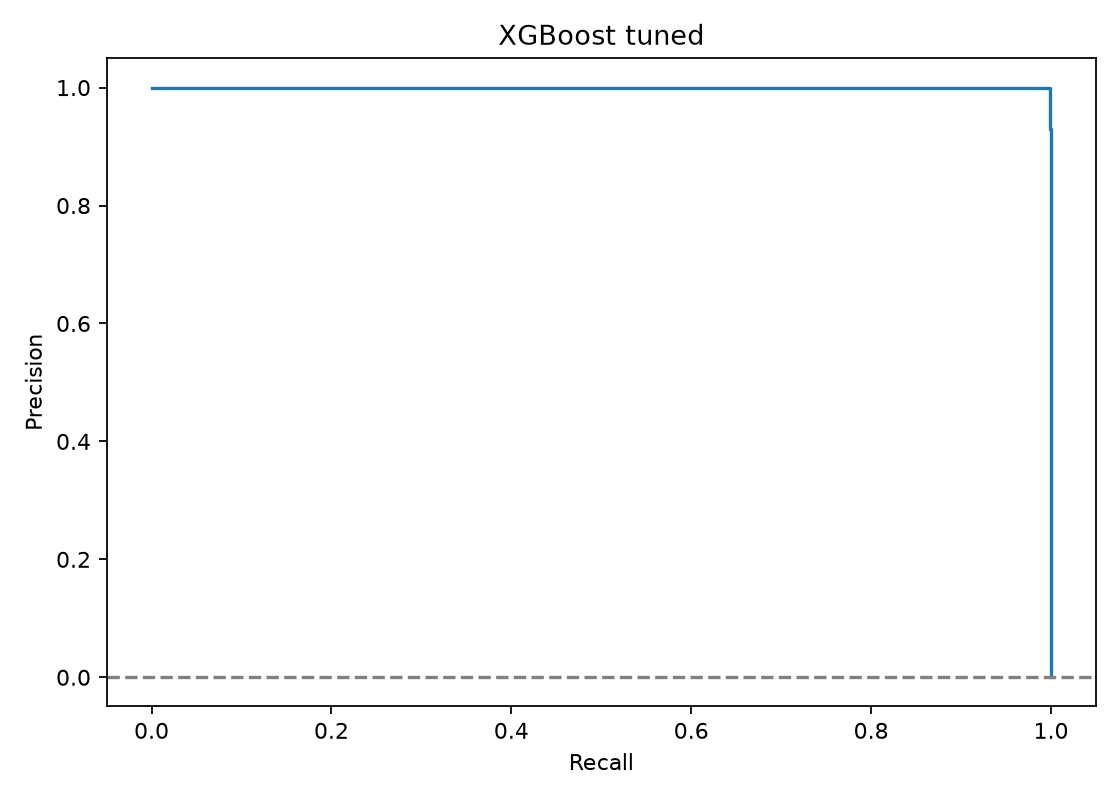

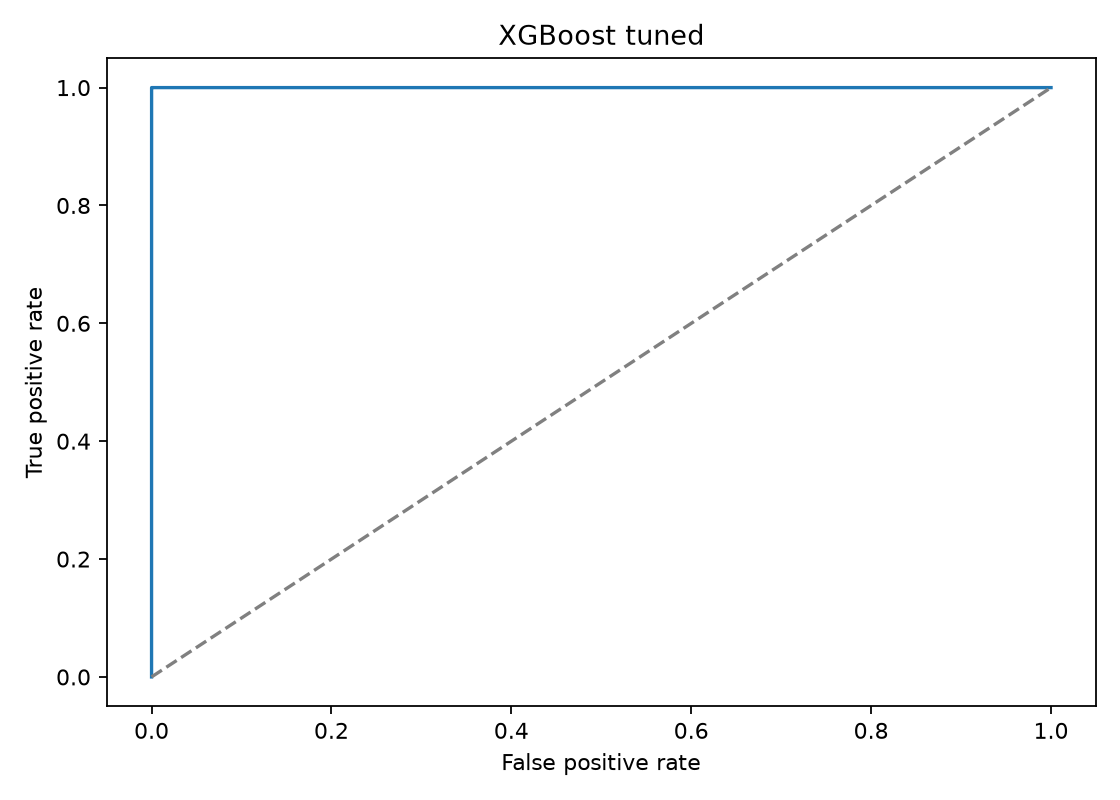

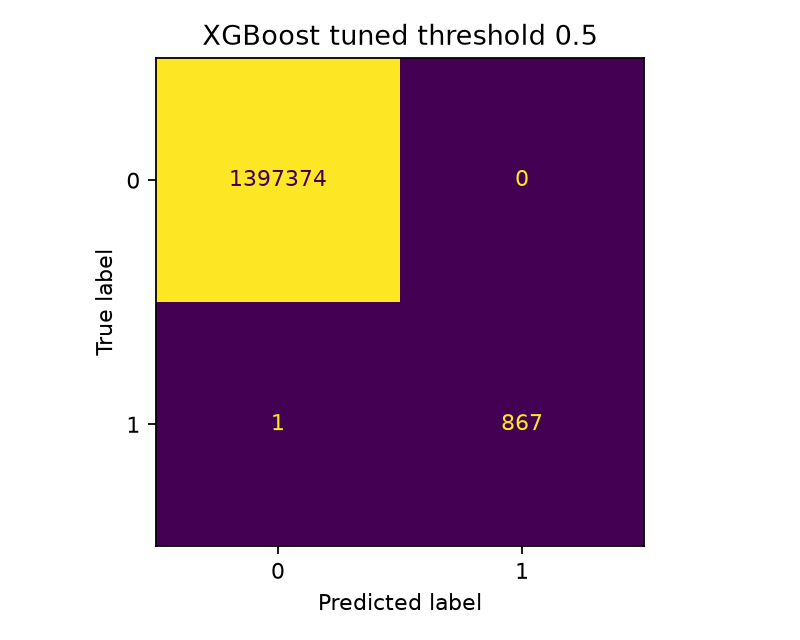

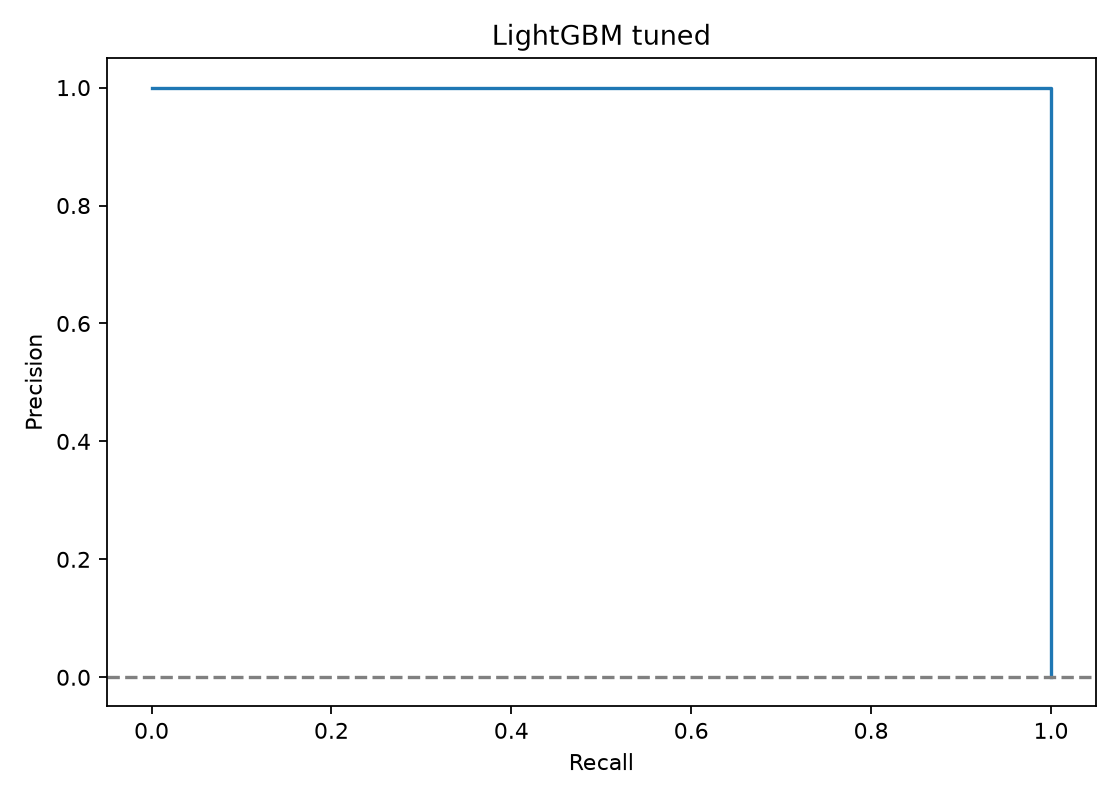

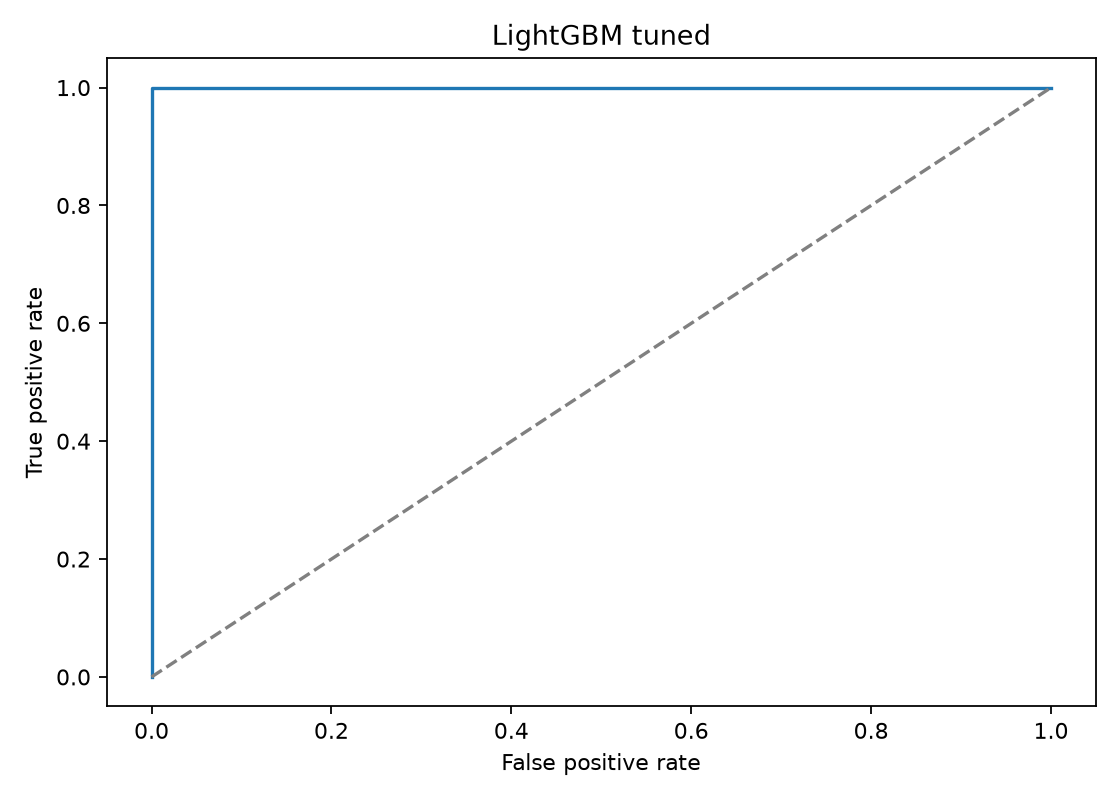

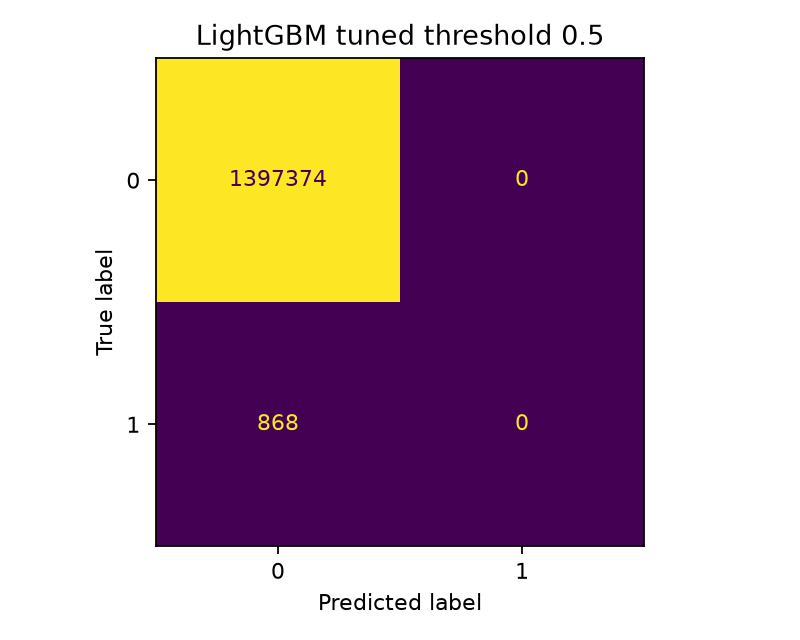

In [5]:
display(comparison)
for algorithm in ['XGBoost','LightGBM']:
    for kind in ['pr','roc','confusion']:
        display(Image(filename=str(ROOT/'reports/figures'/f'phase3_{kind}_{algorithm}.png')))

## Operational review capacity

Recall@Top0.1% is the share of fraud captured among the highest-scored 1,399 transactions. Precision is reviewed-set fraud yield. Validation prevalence is unchanged. Stable row-order ties follow Phase 2 semantics.

In [6]:
display(comparison[['model','variant']+[c for c in comparison.columns if 'top_' in c]])
display(run['provisional_champion'])

,model,variant,precision_top_0.1pct,recall_top_0.1pct,precision_top_0.5pct,recall_top_0.5pct,precision_top_1pct,recall_top_1pct
0,LogisticRegression,baseline,0.619728,0.998848,0.123999,0.998848,0.062004,0.998848
1,RandomForest,baseline,0.620443,1.000000,0.124142,1.000000,0.062075,1.000000
2,XGBoost,baseline,0.620443,1.000000,0.124142,1.000000,0.062075,1.000000
3,LightGBM,baseline,0.620443,1.000000,0.124142,1.000000,0.062075,1.000000
4,XGBoost,tuned,0.620443,1.000000,0.124142,1.000000,0.062075,1.000000
5,LightGBM,tuned,0.620443,1.000000,0.124142,1.000000,0.062075,1.000000


{'model': 'XGBoost', 'variant': 'tuned', 'status': 'PROVISIONAL CHAMPION', 'criterion': 'Tuned candidates within 0.0001 AP of best; full Top0.1% capture preferred; then FN, FP, measured prediction latency, effective iterations, training time and name', 'reason': 'XGBoost in practical AP band, Top0.1% recall=1.000000; threshold 0.5 FN=1, FP=0; prediction=0.187s; effective iterations=24. No statistically proven superiority; times are one-run measurements.'}

## Provisional champion and limitations

XGBoost in practical AP band, Top0.1% recall=1.000000; threshold 0.5 FN=1, FP=0; prediction=0.187s; effective iterations=24. No statistically proven superiority; times are one-run measurements.

The champion is provisional. No final production threshold, evaluation or deployment. The simulator is nearly deterministic, operational balance availability remains uncertain, and repeated use of one holdout can overfit selection. Trial dispersion is not independent generalization evidence. DagsHub remote prerequisites and external experiment link remain pending.

## Reproduce and stop

From repository root: `uv sync --locked`; `uv run python scripts/run_sanity_checks.py`; `uv run python scripts/run_optimization.py`; `uv run python scripts/build_phase3_report.py`. Run `uv run python -m pytest -q` for the synthetic suite. Training logic stays in src/fraud_detection/optimization.py and scripts/run_optimization.py. This notebook loads artifacts; it does not retrain models. Do not continue automatically with SHAP, Production or monitoring.